# Raincloud Plot

**Family:** Distribution &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Distribution:* Show values in a dataset and how often they occur; the shape (skew, spread, gaps) is the story.

## Design purpose

Combines a half-violin (the 'cloud'), a box plot, and jittered raw points (the 'rain'). Shape, summary statistics and every observation appear together, which addresses the main criticism of bar and box plots.

## When to use

- Compare groups in research reports where transparency matters
- Show moderate samples where the shape, the summary and the raw data all matter

## Avoid when

- Space is limited or there are many groups
- The audience is non-technical

## Alternatives

- Violin plot + strip
- Box plot + strip

## Example

Reaction times (ms) under three caffeine conditions, 80 participants each (synthetic).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(37)
conds = {"No caffeine": (420, 60), "1 cup": (385, 50), "3 cups": (395, 75)}
df = pd.concat([pd.DataFrame({"condition": c, "rt_ms": rng.normal(m, s, 80)})
                for c, (m, s) in conds.items()], ignore_index=True)
df.groupby("condition", sort=False)["rt_ms"].describe().round(0)

,count,mean,std,min,25%,50%,75%,max
condition,,,,,,,,
No caffeine,80.0,414.0,62.0,267.0,365.0,415.0,460.0,556.0
1 cup,80.0,386.0,43.0,273.0,360.0,387.0,413.0,479.0
3 cups,80.0,389.0,74.0,200.0,344.0,399.0,439.0,565.0


### Plot

/var/folders/2q/sq_5xvg16ds08bkpx3ll0pxw0000gn/T/ipykernel_6166/3758111861.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  v = ax.violinplot(vals, positions=[i], vert=False, widths=0.9,
/var/folders/2q/sq_5xvg16ds08bkpx3ll0pxw0000gn/T/ipykernel_6166/3758111861.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(vals, positions=[i - 0.08], vert=False, widths=0.07, patch_artist=True,
/var/folders/2q/sq_5xvg16ds08bkpx3ll0pxw0000gn/T/ipykernel_6166/3758111861.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  v = ax.violinplot(vals, positions=[i], vert=False, widths=0.9,
/var/folders/2q/sq_5xvg16ds08bkpx3ll0pxw0000gn/T/ipykernel_6166/375811

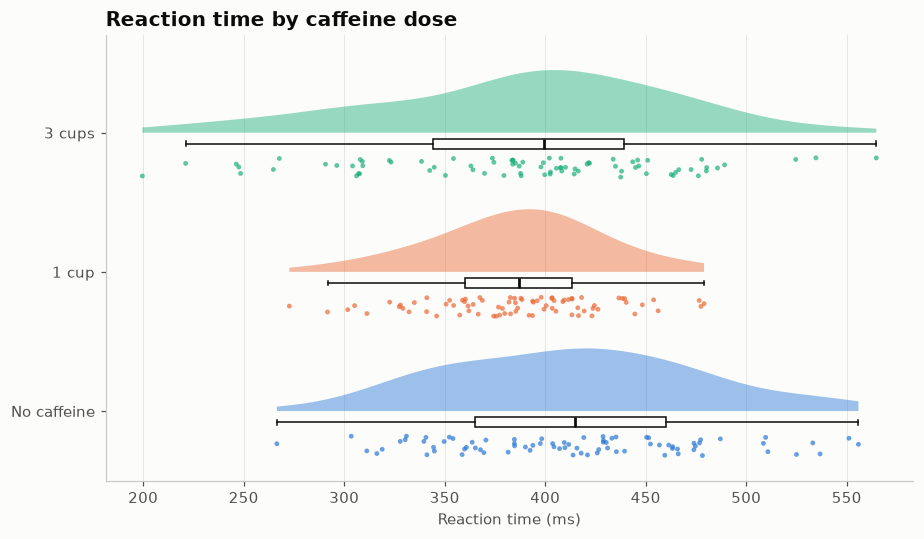

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 5))
groups = list(conds)
rng_j = np.random.default_rng(0)
for i, (g, color) in enumerate(zip(groups, PALETTE)):
    vals = df.loc[df["condition"] == g, "rt_ms"].values
    v = ax.violinplot(vals, positions=[i], vert=False, widths=0.9,
                      showextrema=False)
    body = v["bodies"][0]
    verts = body.get_paths()[0].vertices
    verts[:, 1] = np.clip(verts[:, 1], i, None)       # keep the upper half: the "cloud"
    body.set_facecolor(color); body.set_alpha(0.45); body.set_edgecolor("none")
    ax.boxplot(vals, positions=[i - 0.08], vert=False, widths=0.07, patch_artist=True,
               showfliers=False, boxprops=dict(facecolor="#fcfcfb", edgecolor="#0b0b0b"),
               medianprops=dict(color="#0b0b0b", linewidth=1.8),
               whiskerprops=dict(color="#0b0b0b"), capprops=dict(color="#0b0b0b"))
    ax.scatter(vals, i - 0.25 + rng_j.uniform(-0.07, 0.07, len(vals)), s=10,
               color=color, alpha=0.7, edgecolor="none")
ax.set_yticks(range(len(groups)), groups)
ax.set_ylim(-0.5, len(groups) - 0.3)
ax.set_xlabel("Reaction time (ms)")
ax.set_title("Reaction time by caffeine dose")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

## How to read it

For each condition, the cloud shows the distribution's shape, the box marks the median and quartiles, and the rain shows each participant. One cup is fastest, and three cups widens the spread.

---
Standalone script: [`raincloud.py`](raincloud.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)